<a href="https://colab.research.google.com/github/Yuuraajaa/Tito_Dwi_Saputro_2411007-Sistem_Cerdas/blob/main/Sistem_Cerdas_UTS_2411007_Tito_Dwi_Saputro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-fuzzy xgboost scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import skfuzzy as fuzz
from skfuzzy import control as ctrl

from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from google.colab import files
import warnings

warnings.filterwarnings('ignore')

print("Library berhasil diimport!")

Library berhasil diimport!


In [3]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')
# Path file Datasets
folder_path = '/content/drive/MyDrive/Datasets balita'

file_A_path = os.path.join(folder_path, 'Dataset_A_FIS_SistemPakar_200.csv')
file_B_path = os.path.join(folder_path, 'Dataset_B_XGBoost_200.csv')

# Untuk Validasi file
if os.path.exists(file_A_path) and os.path.exists(file_B_path):
    print("Dataset terdeteksi dan siap digunakan dari Google Drive!")
else:
    print("Peringatan: File tidak ditemukan pada path yang ditentukan!")
    print("Path dicari:")
    print("- Dataset A:", file_A_path)
    print("- Dataset B:", file_B_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset terdeteksi dan siap digunakan dari Google Drive!


In [4]:
import pandas as pd

# Membaca dataset langsung dari path Google Drive
df_A = pd.read_csv(file_A_path)
df_B = pd.read_csv(file_B_path)

rename_dict = {
    'Umur_bulan': 'Umur (bln)',
    'BB_kg': 'BB (kg)',
    'TB_cm': 'TB (cm)',
    'LILA_cm': 'LILA (cm)',
    'ASI_eksklusif_6_bulan': 'ASI Eks.'
}
df_A.rename(columns=rename_dict, inplace=True)
df_B.rename(columns=rename_dict, inplace=True)

print("Dataset A berhasil dimuat dari Google Drive:")
display(df_A.head())

print("\nDataset B berhasil dimuat dari Google Drive:")
display(df_B.head())

Dataset A berhasil dimuat dari Google Drive:


,ID,Nama,Umur (bln),BB (kg),TB (cm),LILA (cm),Jenis_kelamin,ASI Eks.,Status_gizi
0,B01,Andi Pratama,24,10.2,82.0,13.5,Laki-laki,Ya,Normal
1,B02,Siti Rahayu,36,11.8,88.0,12.1,Perempuan,Tidak,Gizi Kurang
2,B03,Budi Santoso,18,7.4,74.0,11.0,Laki-laki,Tidak,Stunting
3,B04,Lena Wulandari,48,15.1,96.0,14.2,Perempuan,Ya,Normal
4,B05,Rizky Aditya,12,6.8,68.0,10.5,Laki-laki,Tidak,Stunting



Dataset B berhasil dimuat dari Google Drive:


,ID,Nama,Umur (bln),BB (kg),TB (cm),LILA (cm),Jenis_kelamin,ASI Eks.,Label_risiko
0,B01,Andi Pratama,24,10.2,82.0,13.5,Laki-laki,Ya,0 (Normal)
1,B02,Siti Rahayu,36,11.8,88.0,12.1,Perempuan,Tidak,1 (Risiko)
2,B03,Budi Santoso,18,7.4,74.0,11.0,Laki-laki,Tidak,1 (Risiko)
3,B04,Lena Wulandari,48,15.1,96.0,14.2,Perempuan,Ya,0 (Normal)
4,B05,Rizky Aditya,12,6.8,68.0,10.5,Laki-laki,Tidak,1 (Risiko)


In [5]:
import pandas as pd
import os

# Menggunakan path dari Google Drive yang sudah didefinisikan sebelumnya
df_A = pd.read_csv(file_A_path)
df_B = pd.read_csv(file_B_path)

rename_dict = {
    'Umur_bulan': 'Umur (bln)',
    'BB_kg': 'BB (kg)',
    'TB_cm': 'TB (cm)',
    'LILA_cm': 'LILA (cm)',
    'ASI_eksklusif_6_bulan': 'ASI Eks.'
}
df_A.rename(columns=rename_dict, inplace=True)
df_B.rename(columns=rename_dict, inplace=True)

print("Dataset A:")
display(df_A.head())

print("\nDataset B:")
display(df_B.head())

print("\nJumlah Dataset A:", df_A.shape)
print("Jumlah Dataset B:", df_B.shape)

Dataset A:


,ID,Nama,Umur (bln),BB (kg),TB (cm),LILA (cm),Jenis_kelamin,ASI Eks.,Status_gizi
0,B01,Andi Pratama,24,10.2,82.0,13.5,Laki-laki,Ya,Normal
1,B02,Siti Rahayu,36,11.8,88.0,12.1,Perempuan,Tidak,Gizi Kurang
2,B03,Budi Santoso,18,7.4,74.0,11.0,Laki-laki,Tidak,Stunting
3,B04,Lena Wulandari,48,15.1,96.0,14.2,Perempuan,Ya,Normal
4,B05,Rizky Aditya,12,6.8,68.0,10.5,Laki-laki,Tidak,Stunting



Dataset B:


,ID,Nama,Umur (bln),BB (kg),TB (cm),LILA (cm),Jenis_kelamin,ASI Eks.,Label_risiko
0,B01,Andi Pratama,24,10.2,82.0,13.5,Laki-laki,Ya,0 (Normal)
1,B02,Siti Rahayu,36,11.8,88.0,12.1,Perempuan,Tidak,1 (Risiko)
2,B03,Budi Santoso,18,7.4,74.0,11.0,Laki-laki,Tidak,1 (Risiko)
3,B04,Lena Wulandari,48,15.1,96.0,14.2,Perempuan,Ya,0 (Normal)
4,B05,Rizky Aditya,12,6.8,68.0,10.5,Laki-laki,Tidak,1 (Risiko)



Jumlah Dataset A: (200, 9)
Jumlah Dataset B: (200, 9)


In [6]:
def estimasi_zscore(umur, bb, tb):

    # Estimasi median BB berdasarkan umur
    if umur < 12:
        median_bb = 3.3 + (0.5 * umur)
        sd_bb = 0.9 + (0.025 * umur)
    else:
        median_bb = 9.3 + (0.19 * (umur - 12))
        sd_bb = 1.2 + (0.018 * umur)

    # Estimasi median TB berdasarkan umur
    if umur < 12:
        median_tb = 49.9 + (2.0 * umur)
        sd_tb = 2.5 + (0.04 * umur)
    else:
        median_tb = 74.7 + (0.78 * (umur - 12))
        sd_tb = 3.0 + (0.025 * umur)

    z_bb = (bb - median_bb) / sd_bb
    z_tb = (tb - median_tb) / sd_tb

    return z_bb, z_tb


df_A[['Z_BB_U', 'Z_TB_U']] = df_A.apply(
    lambda row: pd.Series(
        estimasi_zscore(
            row['Umur (bln)'],
            row['BB (kg)'],
            row['TB (cm)']
        )
    ),
    axis=1
)

display(df_A[
    ['ID', 'Nama', 'Umur (bln)', 'BB (kg)',
     'TB (cm)', 'Z_BB_U', 'Z_TB_U']
].head(10))

,ID,Nama,Umur (bln),BB (kg),TB (cm),Z_BB_U,Z_TB_U
0,B01,Andi Pratama,24,10.2,82.0,-0.845588,-0.572222
1,B02,Siti Rahayu,36,11.8,88.0,-1.114719,-1.389744
2,B03,Budi Santoso,18,7.4,74.0,-1.994751,-1.559420
3,B04,Lena Wulandari,48,15.1,96.0,-0.503876,-1.614286
4,B05,Rizky Aditya,12,6.8,68.0,-1.765537,-2.030303
5,B06,Dewi Kusuma,30,9.5,80.0,-1.850575,-2.330667
6,B07,Farhan Malik,42,13.2,93.0,-0.920245,-1.259259
7,B08,Nur Aisyah,6,5.1,61.0,-1.142857,-0.328467
8,B09,Hendra Pratama,44,6.9,82.3,-4.257028,-4.234146
9,B10,Nisa Puspita,41,11.0,86.0,-1.965944,-2.812422


In [7]:

# Input Z-Score BB/U
zbb = ctrl.Antecedent(
    np.arange(-4, 4.1, 0.1), 'zbb'
)

# Input Z-Score TB/U
ztb = ctrl.Antecedent(
    np.arange(-4, 4.1, 0.1), 'ztb'
)

# Output risiko stunting
output_risiko = ctrl.Consequent(
    np.arange(0, 101, 1), 'risiko'
)

# Membership BB/U
zbb['rendah'] = fuzz.trapmf(
    zbb.universe, [-4, -4, -2, -1]
)

zbb['normal'] = fuzz.trimf(
    zbb.universe, [-2, 0, 2]
)

zbb['tinggi'] = fuzz.trapmf(
    zbb.universe, [1, 2, 4, 4]
)

# Membership TB/U
ztb['rendah'] = fuzz.trapmf(
    ztb.universe, [-4, -4, -2, -1]
)

ztb['normal'] = fuzz.trimf(
    ztb.universe, [-2, 0, 2]
)

ztb['tinggi'] = fuzz.trapmf(
    ztb.universe, [1, 2, 4, 4]
)

# Membership output
output_risiko['rendah'] = fuzz.trapmf(
    output_risiko.universe, [0, 0, 20, 40]
)

output_risiko['sedang'] = fuzz.trimf(
    output_risiko.universe, [25, 50, 75]
)

output_risiko['tinggi'] = fuzz.trapmf(
    output_risiko.universe, [60, 80, 100, 100]
)

print("Variabel FIS Mamdani berhasil dibuat!")


Variabel FIS Mamdani berhasil dibuat!


In [8]:
rules = [
    ctrl.Rule(zbb['rendah'] & ztb['rendah'],
              output_risiko['tinggi']),

    ctrl.Rule(zbb['rendah'] & ztb['normal'],
              output_risiko['sedang']),

    ctrl.Rule(zbb['rendah'] & ztb['tinggi'],
              output_risiko['sedang']),

    ctrl.Rule(zbb['normal'] & ztb['rendah'],
              output_risiko['tinggi']),

    ctrl.Rule(zbb['normal'] & ztb['normal'],
              output_risiko['rendah']),

    ctrl.Rule(zbb['normal'] & ztb['tinggi'],
              output_risiko['rendah']),

    ctrl.Rule(zbb['tinggi'] & ztb['rendah'],
              output_risiko['tinggi']),

    ctrl.Rule(zbb['tinggi'] & ztb['normal'],
              output_risiko['rendah']),

    ctrl.Rule(zbb['tinggi'] & ztb['tinggi'],
              output_risiko['rendah'])
]

fis_control = ctrl.ControlSystem(rules)

print("9 Rule Fuzzy berhasil dibuat!")

9 Rule Fuzzy berhasil dibuat!


In [9]:

def prediksi_fis(z_bb, z_tb):

    simulasi = ctrl.ControlSystemSimulation(fis_control)

    # Membatasi input pada universe fuzzy
    z_bb = np.clip(z_bb, -4, 4)
    z_tb = np.clip(z_tb, -4, 4)

    simulasi.input['zbb'] = z_bb
    simulasi.input['ztb'] = z_tb

    simulasi.compute()

    return simulasi.output['risiko']


df_A['Skor Risiko FIS'] = df_A.apply(
    lambda row: prediksi_fis(
        row['Z_BB_U'],
        row['Z_TB_U']
    ),
    axis=1
)

def kategori_fis(skor):
    if skor < 40:
        return 'NORMAL'
    elif skor < 70:
        return 'GIZI KURANG'
    else:
        return 'STUNTING'

df_A['Kategori FIS'] = df_A['Skor Risiko FIS'].apply(
    kategori_fis
)

display(df_A[
    ['ID', 'Nama', 'Z_BB_U', 'Z_TB_U',
     'Skor Risiko FIS', 'Kategori FIS']
].head(10))

,ID,Nama,Z_BB_U,Z_TB_U,Skor Risiko FIS,Kategori FIS
0,B01,Andi Pratama,-0.845588,-0.572222,17.276200,NORMAL
1,B02,Siti Rahayu,-1.114719,-1.389744,53.353510,GIZI KURANG
2,B03,Budi Santoso,-1.994751,-1.559420,71.841053,STUNTING
3,B04,Lena Wulandari,-0.503876,-1.614286,66.230240,GIZI KURANG
4,B05,Rizky Aditya,-1.765537,-2.030303,83.525703,STUNTING
5,B06,Dewi Kusuma,-1.850575,-2.330667,83.870011,STUNTING
6,B07,Farhan Malik,-0.920245,-1.259259,44.636765,GIZI KURANG
7,B08,Nur Aisyah,-1.142857,-0.328467,27.218161,NORMAL
8,B09,Hendra Pratama,-4.257028,-4.234146,84.444444,STUNTING
9,B10,Nisa Puspita,-1.965944,-2.812422,84.317180,STUNTING


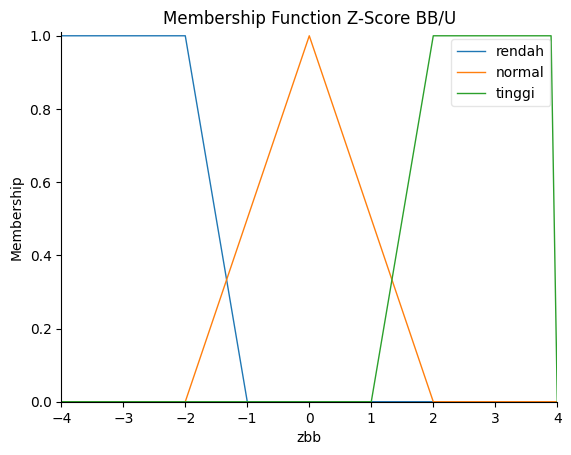

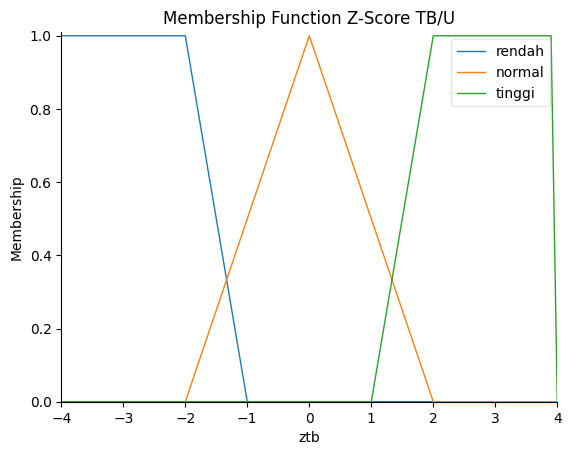

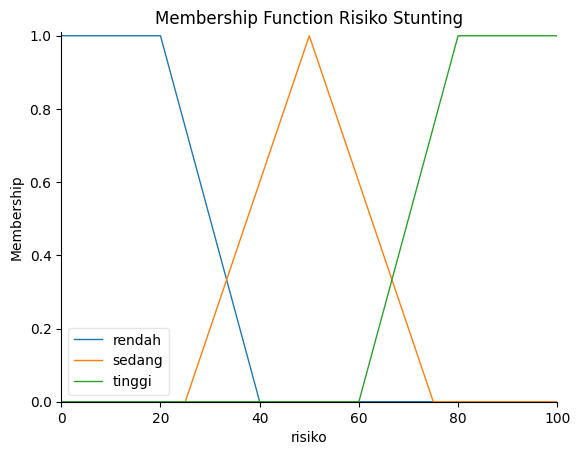

In [10]:
zbb.view()
plt.title('Membership Function Z-Score BB/U')
plt.show()

ztb.view()
plt.title('Membership Function Z-Score TB/U')
plt.show()

output_risiko.view()
plt.title('Membership Function Risiko Stunting')
plt.show()

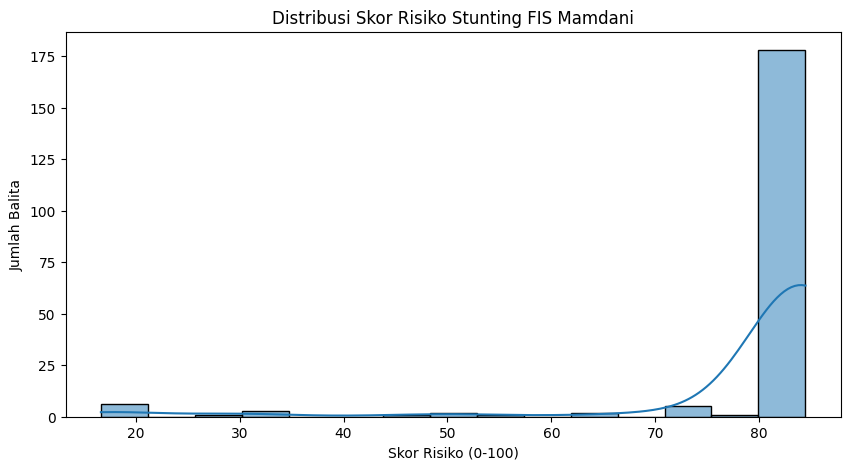

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df_A['Skor Risiko FIS'],
    bins=15,
    kde=True
)

plt.title('Distribusi Skor Risiko Stunting FIS Mamdani')
plt.xlabel('Skor Risiko (0-100)')
plt.ylabel('Jumlah Balita')

plt.show()

In [12]:
rules_pakar = [
    {
        'nama': 'R1',
        'kondisi': lambda f: f['z_tb'] < -2 and f['risiko'] >= 70,
        'diagnosa': 'STUNTING',
        'rekomendasi': 'Rujuk ke Puskesmas untuk pemeriksaan pertumbuhan dan evaluasi gizi.'
    },
    {
        'nama': 'R2',
        'kondisi': lambda f: f['z_tb'] < -2,
        'diagnosa': 'STUNTING',
        'rekomendasi': 'Lakukan pemeriksaan TB/U dan pemantauan pertumbuhan secara berkala.'
    },
    {
        'nama': 'R3',
        'kondisi': lambda f: f['z_bb'] < -2 and f['lila'] < 12.5,
        'diagnosa': 'GIZI KURANG',
        'rekomendasi': 'Konsultasi gizi dan evaluasi asupan makanan balita.'
    },
    {
        'nama': 'R4',
        'kondisi': lambda f: f['z_bb'] < -2,
        'diagnosa': 'GIZI KURANG',
        'rekomendasi': 'Lakukan pemeriksaan BB/U dan perbaikan pola makan.'
    },
    {
        'nama': 'R5',
        'kondisi': lambda f: f['lila'] < 12.5 and f['risiko'] >= 40,
        'diagnosa': 'GIZI KURANG',
        'rekomendasi': 'Lakukan pemeriksaan status gizi dan konsultasi tenaga kesehatan.'
    },
    {
        'nama': 'R6',
        'kondisi': lambda f: f['risiko'] >= 40,
        'diagnosa': 'GIZI KURANG',
        'rekomendasi': 'Pantau berat badan dan konsultasikan hasil pemeriksaan ke petugas gizi.'
    },
    {
        'nama': 'R7',
        'kondisi': lambda f: f['z_bb'] >= -2 and f['z_tb'] >= -2 and f['lila'] >= 12.5,
        'diagnosa': 'NORMAL',
        'rekomendasi': 'Pertahankan pola makan bergizi seimbang dan pemantauan rutin.'
    },
    {
        'nama': 'R8',
        'kondisi': lambda f: f['risiko'] < 40 and f['z_tb'] >= -2,
        'diagnosa': 'NORMAL',
        'rekomendasi': 'Lanjutkan pemantauan pertumbuhan dan perkembangan balita.'
    },
    {
        'nama': 'R9',
        'kondisi': lambda f: f['asi'] == 'Tidak' and f['umur'] <= 6,
        'diagnosa': 'GIZI KURANG',
        'rekomendasi': 'Konsultasikan praktik pemberian ASI dan pemenuhan nutrisi kepada tenaga kesehatan.'
    }
]

print("Jumlah rule sistem pakar:", len(rules_pakar))

Jumlah rule sistem pakar: 9


In [13]:
def forward_chaining(row):

    # Working Memory awal
    wm = {
        'umur': row['Umur (bln)'],
        'bb': row['BB (kg)'],
        'tb': row['TB (cm)'],
        'lila': row['LILA (cm)'],
        'z_bb': row['Z_BB_U'],
        'z_tb': row['Z_TB_U'],
        'risiko': row['Skor Risiko FIS'],
        'asi': 'Tidak'
    }

    # Mengambil ASI dari Dataset B jika tersedia
    if row['ID'] in df_B['ID'].values:
        asi_data = df_B.loc[
            df_B['ID'] == row['ID'], 'ASI Eks.'
        ].iloc[0]

        wm['asi'] = str(asi_data)

    print("WORKING MEMORY AWAL:")
    print(wm)

    hasil_rule = []
    kesimpulan = None
    rekomendasi = None

    # Prioritas rule: stunting > gizi kurang > normal
    prioritas = {
        'STUNTING': 3,
        'GIZI KURANG': 2,
        'NORMAL': 1
    }

    for rule in rules_pakar:

        if rule['kondisi'](wm):

            print("\nMATCH:", rule['nama'])

            print("FIRED:", rule['nama'])

            hasil_rule.append(rule['nama'])

            # Memperbarui working memory
            wm['diagnosa'] = rule['diagnosa']

            if kesimpulan is None or prioritas[
                rule['diagnosa']
            ] > prioritas[kesimpulan]:

                kesimpulan = rule['diagnosa']
                rekomendasi = rule['rekomendasi']

            print("WORKING MEMORY BARU:")
            print(wm)

    if kesimpulan is None:
        kesimpulan = 'PERLU PEMERIKSAAN LANJUT'
        rekomendasi = 'Lakukan pemeriksaan antropometri lengkap di Puskesmas.'

    return {
        'rule_fired': ', '.join(hasil_rule),
        'diagnosa': kesimpulan,
        'rekomendasi': rekomendasi
    }

In [14]:
hasil_pakar = df_A.apply(
    forward_chaining,
    axis=1
)

df_A['Rule Fired'] = [
    hasil['rule_fired'] for hasil in hasil_pakar
]

df_A['Diagnosa Pakar'] = [
    hasil['diagnosa'] for hasil in hasil_pakar
]

df_A['Rekomendasi'] = [
    hasil['rekomendasi'] for hasil in hasil_pakar
]

display(df_A[
    ['ID', 'Nama', 'Diagnosa Pakar', 'Rule Fired', 'Rekomendasi']
].head(10))

WORKING MEMORY AWAL:
{'umur': 24, 'bb': 10.2, 'tb': 82.0, 'lila': 13.5, 'z_bb': -0.8455882352941193, 'z_tb': -0.5722222222222229, 'risiko': 17.276199953665685, 'asi': 'Ya'}

MATCH: R7
FIRED: R7
WORKING MEMORY BARU:
{'umur': 24, 'bb': 10.2, 'tb': 82.0, 'lila': 13.5, 'z_bb': -0.8455882352941193, 'z_tb': -0.5722222222222229, 'risiko': 17.276199953665685, 'asi': 'Ya', 'diagnosa': 'NORMAL'}

MATCH: R8
FIRED: R8
WORKING MEMORY BARU:
{'umur': 24, 'bb': 10.2, 'tb': 82.0, 'lila': 13.5, 'z_bb': -0.8455882352941193, 'z_tb': -0.5722222222222229, 'risiko': 17.276199953665685, 'asi': 'Ya', 'diagnosa': 'NORMAL'}
WORKING MEMORY AWAL:
{'umur': 36, 'bb': 11.8, 'tb': 88.0, 'lila': 12.1, 'z_bb': -1.114718614718615, 'z_tb': -1.3897435897435901, 'risiko': 53.35350993809675, 'asi': 'Tidak'}

MATCH: R5
FIRED: R5
WORKING MEMORY BARU:
{'umur': 36, 'bb': 11.8, 'tb': 88.0, 'lila': 12.1, 'z_bb': -1.114718614718615, 'z_tb': -1.3897435897435901, 'risiko': 53.35350993809675, 'asi': 'Tidak', 'diagnosa': 'GIZI KURANG'}

,ID,Nama,Diagnosa Pakar,Rule Fired,Rekomendasi
0,B01,Andi Pratama,NORMAL,"R7, R8",Pertahankan pola makan bergizi seimbang dan pe...
1,B02,Siti Rahayu,GIZI KURANG,"R5, R6",Lakukan pemeriksaan status gizi dan konsultasi...
2,B03,Budi Santoso,GIZI KURANG,"R5, R6",Lakukan pemeriksaan status gizi dan konsultasi...
3,B04,Lena Wulandari,GIZI KURANG,"R6, R7",Pantau berat badan dan konsultasikan hasil pem...
4,B05,Rizky Aditya,STUNTING,"R1, R2, R5, R6",Rujuk ke Puskesmas untuk pemeriksaan pertumbuh...
5,B06,Dewi Kusuma,STUNTING,"R1, R2, R6",Rujuk ke Puskesmas untuk pemeriksaan pertumbuh...
6,B07,Farhan Malik,GIZI KURANG,"R6, R7",Pantau berat badan dan konsultasikan hasil pem...
7,B08,Nur Aisyah,GIZI KURANG,"R8, R9",Konsultasikan praktik pemberian ASI dan pemenu...
8,B09,Hendra Pratama,STUNTING,"R1, R2, R3, R4, R5, R6",Rujuk ke Puskesmas untuk pemeriksaan pertumbuh...
9,B10,Nisa Puspita,STUNTING,"R1, R2, R6",Rujuk ke Puskesmas untuk pemeriksaan pertumbuh...


In [15]:
siti = df_A[df_A['ID'] == 'B02'].iloc[0]

print("================================")
print("FORWARD CHAINING BALITA B02")
print("================================")

hasil_siti = forward_chaining(siti)

print("\n================================")
print("KESIMPULAN AKHIR B02")
print("================================")

print("Nama:", siti['Nama'])
print("Umur:", siti['Umur (bln)'], "bulan")
print("BB:", siti['BB (kg)'], "kg")
print("TB:", siti['TB (cm)'], "cm")
print("LILA:", siti['LILA (cm)'], "cm")
print("Z-Score BB/U:", round(siti['Z_BB_U'], 2))
print("Z-Score TB/U:", round(siti['Z_TB_U'], 2))
print("Skor Risiko FIS:", round(siti['Skor Risiko FIS'], 2))

print("Rule Fired:", hasil_siti['rule_fired'])
print("Diagnosa:", hasil_siti['diagnosa'])
print("Rekomendasi:", hasil_siti['rekomendasi'])

FORWARD CHAINING BALITA B02
WORKING MEMORY AWAL:
{'umur': np.int64(36), 'bb': np.float64(11.8), 'tb': np.float64(88.0), 'lila': np.float64(12.1), 'z_bb': np.float64(-1.114718614718615), 'z_tb': np.float64(-1.3897435897435901), 'risiko': np.float64(53.35350993809675), 'asi': 'Tidak'}

MATCH: R5
FIRED: R5
WORKING MEMORY BARU:
{'umur': np.int64(36), 'bb': np.float64(11.8), 'tb': np.float64(88.0), 'lila': np.float64(12.1), 'z_bb': np.float64(-1.114718614718615), 'z_tb': np.float64(-1.3897435897435901), 'risiko': np.float64(53.35350993809675), 'asi': 'Tidak', 'diagnosa': 'GIZI KURANG'}

MATCH: R6
FIRED: R6
WORKING MEMORY BARU:
{'umur': np.int64(36), 'bb': np.float64(11.8), 'tb': np.float64(88.0), 'lila': np.float64(12.1), 'z_bb': np.float64(-1.114718614718615), 'z_tb': np.float64(-1.3897435897435901), 'risiko': np.float64(53.35350993809675), 'asi': 'Tidak', 'diagnosa': 'GIZI KURANG'}

KESIMPULAN AKHIR B02
Nama: Siti Rahayu
Umur: 36 bulan
BB: 11.8 kg
TB: 88.0 cm
LILA: 12.1 cm
Z-Score BB/U: -

In [16]:
# Salinan dataset
data = df_B.copy()

# Mengubah ASI Eksklusif menjadi angka
data['ASI Eks.'] = data['ASI Eks.'].astype(str).str.strip().map({
    'Ya': 1,
    'Tidak': 0
})

# Mengubah Jenis Kelamin menjadi angka (Laki-laki: 1, Perempuan: 0)
data['Jenis_kelamin'] = data['Jenis_kelamin'].astype(str).str.strip().map({
    'Laki-laki': 1,
    'Perempuan': 0
})

# Membuat kolom 'Label' berdasarkan 'Label_risiko' yang baru
data['Label'] = data['Label_risiko'].astype(str).str.strip().map({
    '0 (Normal)': 0,
    '1 (Risiko)': 1,
    '0': 0,
    '1': 1
})

# Membersihkan data kosong
data = data.dropna(
    subset=[
        'Umur (bln)', 'BB (kg)', 'TB (cm)',
        'LILA (cm)', 'Jenis_kelamin', 'ASI Eks.', 'Label'
    ]
)

data['Label'] = data['Label'].astype(int)

print("Dataset siap digunakan!")
display(data.head())

Dataset siap digunakan!


,ID,Nama,Umur (bln),BB (kg),TB (cm),LILA (cm),Jenis_kelamin,ASI Eks.,Label_risiko,Label
0,B01,Andi Pratama,24,10.2,82.0,13.5,1,1,0 (Normal),0
1,B02,Siti Rahayu,36,11.8,88.0,12.1,0,0,1 (Risiko),1
2,B03,Budi Santoso,18,7.4,74.0,11.0,1,0,1 (Risiko),1
3,B04,Lena Wulandari,48,15.1,96.0,14.2,0,1,0 (Normal),0
4,B05,Rizky Aditya,12,6.8,68.0,10.5,1,0,1 (Risiko),1


In [17]:
X = data[
    [
        'Umur (bln)',
        'BB (kg)',
        'TB (cm)',
        'LILA (cm)',
        'Jenis_kelamin',
        'ASI Eks.'
    ]
]

y = data['Label']

print("Fitur:")
display(X.head())

print("\nTarget:")
display(y.head())

print("\nDistribusi Label:")
print(y.value_counts())

Fitur:


,Umur (bln),BB (kg),TB (cm),LILA (cm),Jenis_kelamin,ASI Eks.
0,24,10.2,82.0,13.5,1,1
1,36,11.8,88.0,12.1,0,0
2,18,7.4,74.0,11.0,1,0
3,48,15.1,96.0,14.2,0,1
4,12,6.8,68.0,10.5,1,0



Target:


,Label
0,0
1,1
2,1
3,0
4,1



Distribusi Label:
Label
0    124
1     76
Name: count, dtype: int64


In [18]:

X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X,
    y,
    data.index,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data Training:", len(X_train))
print("Data Testing:", len(X_test))


Data Training: 160
Data Testing: 40


In [19]:
# 1. Definisikan Base Model XGBoost
xgb_base = XGBClassifier(random_state=42, eval_metric='logloss')

# 2. Definisikan Grid Parameter (Minimal 5 Hyperparameter untuk ditalas/dituning)
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 0.9]
}

# 3. Stratified 5-Fold Cross-Validation sesuai ketentuan UTS
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 4. Pencarian GridSearch dengan Stratified CV
grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    cv=cv_stratified,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

print("Memulai proses Tuning Hyperparameter dengan Stratified 5-Fold CV...")
grid_search.fit(X_train, y_train)

# Simpan model terbaik hasil tuning
model = grid_search.best_estimator_

print("\nHyperparameter Terbaik Hasil Tuning:")
print(grid_search.best_params_)

Memulai proses Tuning Hyperparameter dengan Stratified 5-Fold CV...
Fitting 5 folds for each of 243 candidates, totalling 1215 fits

Hyperparameter Terbaik Hasil Tuning:
{'colsample_bytree': 0.9, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 150, 'subsample': 0.8}


In [20]:

y_pred = model.predict(X_test)

print("Prediksi XGBoost:")
print(y_pred)

print("\nLabel Aktual:")
print(y_test.values)


Prediksi XGBoost:
[0 1 0 0 0 1 0 0 1 1 0 0 0 0 0 0 0 0 1 0 0 0 1 1 0 0 0 0 0 1 0 1 0 0 0 0 1
 1 1 1]

Label Aktual:
[0 0 0 0 1 1 1 1 1 1 0 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 1 0 1 0 0 0 0 1
 1 1 1]


In [21]:
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

akurasi = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("HASIL EVALUASI XGBOOST (SETELAH TUNING & CV)")
print("==========================================")
print("Accuracy :", round(akurasi * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1-Score :", round(f1 * 100, 2), "%")
print("ROC-AUC  :", round(roc_auc * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Normal', 'Risiko Stunting'],
    zero_division=0
))

HASIL EVALUASI XGBOOST (SETELAH TUNING & CV)
Accuracy : 85.0 %
Precision: 84.62 %
Recall   : 73.33 %
F1-Score : 78.57 %
ROC-AUC  : 85.33 %

Classification Report:
                 precision    recall  f1-score   support

         Normal       0.85      0.92      0.88        25
Risiko Stunting       0.85      0.73      0.79        15

       accuracy                           0.85        40
      macro avg       0.85      0.83      0.84        40
   weighted avg       0.85      0.85      0.85        40



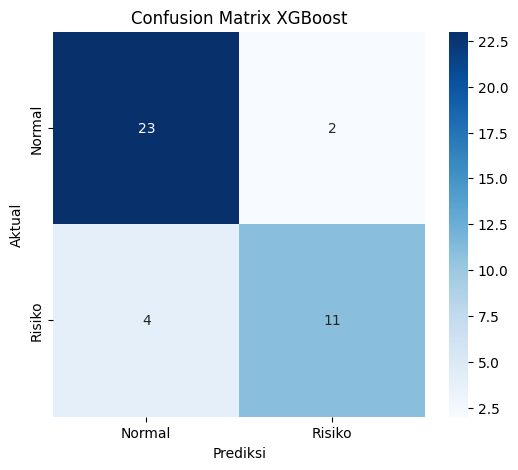

In [22]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Risiko'],
    yticklabels=['Normal', 'Risiko']
)

plt.title('Confusion Matrix XGBoost')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')

plt.show()


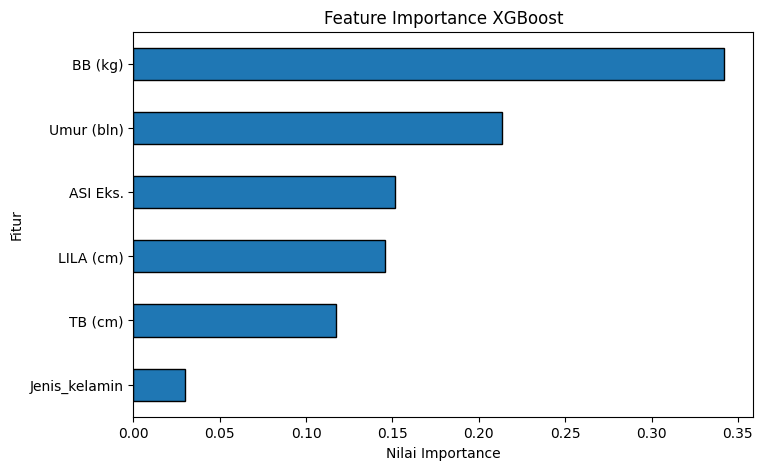

In [23]:

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(8, 5))

importance.plot(
    kind='barh',
    edgecolor='black'
)

plt.title('Feature Importance XGBoost')
plt.xlabel('Nilai Importance')
plt.ylabel('Fitur')

plt.show()


In [24]:

# Mengambil hasil testing XGBoost
hasil_test = data.loc[idx_test, ['ID', 'Label']].copy()

hasil_test['Prediksi XGBoost'] = y_pred

# Menyiapkan hasil FIS dan Sistem Pakar
hasil_A = df_A[
    ['ID', 'Skor Risiko FIS', 'Diagnosa Pakar']
].copy()

# Menggabungkan berdasarkan ID
perbandingan = hasil_test.merge(
    hasil_A,
    on='ID',
    how='inner'
)

# Mengubah hasil FIS menjadi klasifikasi biner
perbandingan['Prediksi FIS'] = (
    perbandingan['Skor Risiko FIS'] >= 40
).astype(int)

# Mengubah hasil sistem pakar menjadi klasifikasi biner
perbandingan['Prediksi Sistem Pakar'] = (
    perbandingan['Diagnosa Pakar'] != 'NORMAL'
).astype(int)

display(perbandingan.head(20))

print("Jumlah data yang berhasil dibandingkan:",
      len(perbandingan))


,ID,Label,Prediksi XGBoost,Skor Risiko FIS,Diagnosa Pakar,Prediksi FIS,Prediksi Sistem Pakar
0,B40,0,0,30.394689,GIZI KURANG,0,1
1,B24,0,1,84.444444,STUNTING,1,1
2,B49,0,0,84.444444,STUNTING,1,1
3,B31,0,0,84.444444,STUNTING,1,1
4,B80,1,0,84.444444,STUNTING,1,1
5,B100,1,1,84.444444,STUNTING,1,1
6,B02,1,0,53.353510,GIZI KURANG,1,1
7,B08,1,0,27.218161,GIZI KURANG,0,1
8,B62,1,1,84.444444,STUNTING,1,1
9,B84,1,1,84.444444,STUNTING,1,1


Jumlah data yang berhasil dibandingkan: 40


In [25]:
y_aktual = perbandingan['Label']

# Definisikan probabilitas untuk penghitungan ROC-AUC pada perbandingan
# (Untuk FIS, kita gunakan Skor Risiko / 100 sebagai proxy probabilitas)
proba_fis = perbandingan['Skor Risiko FIS'] / 100.0
proba_pakar = perbandingan['Prediksi Sistem Pakar'].astype(float) # biner karena berbasis rule konkrit
proba_xgb = model.predict_proba(X_test)[:, 1]

hasil_perbandingan = {
    'FIS Mamdani': (perbandingan['Prediksi FIS'], proba_fis),
    'Sistem Pakar': (perbandingan['Prediksi Sistem Pakar'], proba_pakar),
    'XGBoost': (perbandingan['Prediksi XGBoost'], proba_xgb)
}

evaluasi = []

for nama, (prediksi, proba) in hasil_perbandingan.items():
    evaluasi.append({
        'Metode': nama,
        'Accuracy (%)': accuracy_score(y_aktual, prediksi) * 100,
        'Precision (%)': precision_score(y_aktual, prediksi, zero_division=0) * 100,
        'Recall (%)': recall_score(y_aktual, prediksi, zero_division=0) * 100,
        'F1-Score (%)': f1_score(y_aktual, prediksi, zero_division=0) * 100,
        'ROC-AUC (%)': roc_auc_score(y_aktual, proba) * 100
    })

tabel_evaluasi = pd.DataFrame(evaluasi)
display(tabel_evaluasi.round(2))

,Metode,Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC (%)
0,FIS Mamdani,40.0,37.84,93.33,53.85,57.07
1,Sistem Pakar,37.5,37.50,100.00,54.55,50.00
2,XGBoost,85.0,84.62,73.33,78.57,85.33


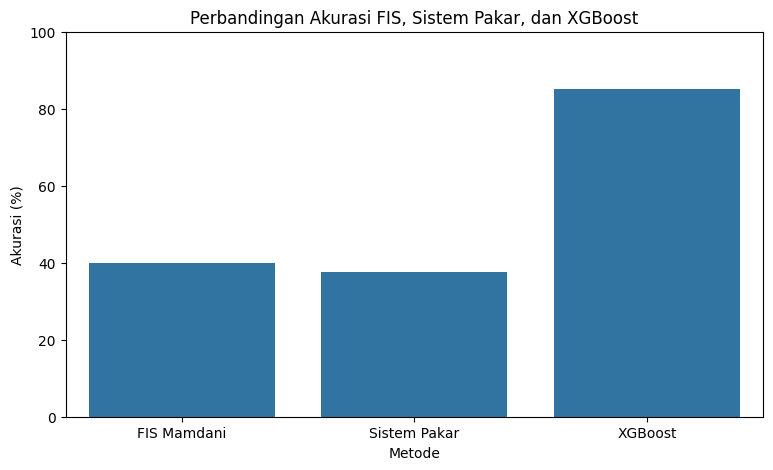

In [26]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=tabel_evaluasi,
    x='Metode',
    y='Accuracy (%)'
)

plt.title('Perbandingan Akurasi FIS, Sistem Pakar, dan XGBoost')
plt.xlabel('Metode')
plt.ylabel('Akurasi (%)')
plt.ylim(0, 100)

plt.show()
